# 第三次作业：基于CIFAR数据集的计算机视觉图像分类  

## 在手写数字识别的代码框架上：
1. 将数据集替换为CIFAR-10和CIFAR-100
2. 分别通过调整网络结构、激活函数、损失函数、训练轮次、批大小和学习率调度等参数来优化模型。
3. 通过实验比较不同模型结构和参数组合在这两个数据集上的表现，并分析这些调整对模型精度和收敛速度的影响，以构建适用于CIFAR数据集的最佳深度学习模型。

## 评分标准如下：
1. 实验完备性：要求实验设计周全，包括对CIFAR-10和CIFAR-100的完整数据预处理、多种网络结构的尝试以及参数的多样性调整。实验记录应详细完整，便于结果的分析和复现。
2. 模型准确率：评估模型在CIFAR-10和CIFAR-100测试集上的最终测试准确率，表现出良好的模型调优和训练效果。

# 实验过程总结
<font color=#ff0000>**初次实验结果**</font>
1. 采用与老师类似的CNN框架构建，并未对学习率、batch、epoch作出太大修改，也没有加入防止过拟合的设置。
2. 结果：epoch均为10，学习率均为0.01的情况下，CIFAR_10准确率为80%，CIFAR_100准确率为30.4%
3. 根据记录和存储的数据，发现CIFAR_10后期Loss波动较大，时有回弹，而前期收敛较慢；CIFAR_100在10个epoch中一直收敛很慢，Loss从刚开始的4.45收敛至2.23。
> if i % 100 == 99:  # 每100个batch打印一次训练状态
>     print(f"Epoch {epoch + 1}, Batch {i + 1}, Loss: {running_loss / 100:.3f}, Learning Rate: {scheduler.get_last_lr()}")
>     running_loss = 0.0
>
> 保存模型参数，每个epoch保存一次
> torch.save(model.state_dict(), f"{save_path}/epoch_{epoch + 1}_model.pth")

<font color=#ff0000>**部分修改尝试**</font>
1. 修改函数，把CIFAR_10和CIFAR_100的参数分开，方便后续操作。
2. 首先改变基础参数，学习率分别改为0.005和0.001，CIFAR_100 epoch增加为25。
3. 观察数据发现前期收敛依旧很慢，后期Loss数据经常来回跳跃波动，于是使用scheduler.step()规划学习率。CIFAR_10最终的loss可降至0.04左右，但是准确率仍然在75%左右，无太大变化。loss过于小对测试结果反而不太好，或许是过拟合了。
4. CIFAR_100的准确率提升不显著，于是先在这组采用了dropout()防止过拟合，实验结果略有提升。
5. 一些失败的尝试：模型与优化器均做过一些尝试，对于CIFAR_100尝试换过ResNet，感觉不如增加网络的深度（更多的卷积层和全连接层）；优化器换成Adam的，后来因为和scheduler.step()不适配又换回了SGD。




In [2]:
# 导入需要的库
import os
import torch 
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.transforms import ToPILImage
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim  
# 定义显示函数
show = ToPILImage()


In [3]:
# CIFAR 标准的归一化
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])
# CIFAR_100 数据加强
transform_train_100 = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])
# 下载数据集
from torchvision.datasets import CIFAR10, CIFAR100
from torch.utils.data import DataLoader

# CIFAR-10数据集 ***数据集在加载时使用了 transform
train_dataset = CIFAR10(root='./data', train=True, download=True, transform=transform)
test_dataset = CIFAR10(root='./data', train=False, download=True,transform=transform)

# CIFAR-100数据集 ***数据集在加载时使用了 transform
train_dataset_100 = CIFAR100(root='./data', train=True, download=True, transform=transform_train_100)
test_dataset_100 = CIFAR100(root='./data', train=False, download=True, transform=transform_train_100)

# 数据加载器设置
batch_size=64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
train_loader_100 = DataLoader(train_dataset_100, batch_size=batch_size, shuffle=True)
test_loader_100 = DataLoader(test_dataset_100, batch_size=batch_size, shuffle=False)


Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified
Files already downloaded and verified


In [6]:
# 展示两个数据集的内容
# CIFAR-10和100 的类别
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
classes_100 = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 
    'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 
    'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 
    'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 
    'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 
    'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 
    'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 
    'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 'possum', 
    'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 'sea', 'seal', 'shark', 
    'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 'spider', 'squirrel', 'streetcar', 
    'sunflower', 'sweet_pepper', 'table', 'tank', 'telephone', 'television', 'tiger', 
    'tractor', 'train', 'trout', 'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 
    'wolf', 'woman', 'worm'
]

print(len(train_dataset)) # 训练集大小
print(train_dataset[0][0].size()) # 第 1 条数据的图像大小
print(train_dataset[0][1]) # 第 1 条数据的标签
print(classes[train_dataset[0][1]]) # 第 1 条数据的文本标签

print(len(train_dataset_100)) # 训练集大小
print(train_dataset_100[0][0].size()) # 第 1 条数据的图像大小
print(train_dataset_100[0][1]) # 第 1 条数据的标签
print(classes_100[train_dataset_100[0][1]]) # 第 1 条数据的文本标签

50000
torch.Size([3, 32, 32])
6
frog
50000
torch.Size([3, 32, 32])
19
cattle


CIFAR-10 数据集样本:
图像大小: torch.Size([3, 32, 32])
标签 (整数): 1
标签 (文本): automobile


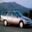

In [8]:
# 展示两个数据集的内容
# 观察数据集CIFAR_10内容
(data, label) = train_dataset[4] # 选群训练集的一个样本展示内容
print("CIFAR-10 数据集样本:")
print("图像大小:", data.size()) 
print("标签 (整数):", label)
print("标签 (文本):", classes[label])

# 显示反归一化的图像
data = data * torch.tensor((0.2023, 0.1994, 0.2010)).view(3, 1, 1) + torch.tensor((0.4914, 0.4822, 0.4465)).view(3, 1, 1)  # 反归一化
show(data)  # 转换为 PIL 格式并显示
 


CIFAR-100 数据集样本:
图像大小: torch.Size([3, 32, 32])
标签 (整数): 89
标签 (文本): tractor


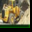

In [10]:
# 展示两个数据集的内容
# 观察CIFAR_100数据集内容
(data_100, label_100) = train_dataset_100[76]  # 选择训练集的一个样本展示内容
print("\nCIFAR-100 数据集样本:")
print("图像大小:", data_100.size()) 
print("标签 (整数):", label_100)
print("标签 (文本):", classes_100[label_100])
data_100 = data_100 * torch.tensor((0.2023, 0.1994, 0.2010)).view(3, 1, 1) + torch.tensor((0.4914, 0.4822, 0.4465)).view(3, 1, 1)  # 反归一化
show(data_100)  # 转换为 PIL 格式并显示


In [ ]:
# 构建CIFAR_10 CNN模型
class SimpleCNN_10(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleCNN_10, self).__init__()
        # 第一层卷积：输入通道3，输出通道16，卷积核大小3x3，步长1，填充1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1)
        # 第一层池化：使用2x2的窗口进行最大池化
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # 第二层卷积：输入通道16，输出通道32，卷积核大小3x3，步长1，填充1
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1)
        # 第三层卷积：输入通道32，输出通道64，卷积核大小3x3，步长1，填充1
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        # 全连接层：输入特征数 64*4*4（假设经过池化后的图像大小为4x4），输出特征数 128
        self.fc1 = nn.Linear(in_features=64*4*4, out_features=128)
        # 最后一个全连接层：输入128个特征，输出num_classes个类别
        self.fc2 = nn.Linear(in_features=128, out_features=num_classes)
        
    def forward(self, x):
        # 第一层卷积 + 激活 + 池化
        x = self.pool(F.relu(self.conv1(x)))
        # 第二层卷积 + 激活 + 池化
        x = self.pool(F.relu(self.conv2(x)))
        # 第三层卷积 + 激活 + 池化
        x = self.pool(F.relu(self.conv3(x)))
        # 扁平化操作：将多维特征展平成一维特征向量
        x = x.view(-1, 64*4*4)
        # 第一个全连接层 + 激活
        x = F.relu(self.fc1(x))
        # 第二个全连接层（输出层）
        x = self.fc2(x)
        
        return x

In [ ]:
# 构建CIFAR_100 CNN模型
class SimpleCNN_100(nn.Module):
    def __init__(self, num_classes=100):
        super(SimpleCNN_100, self).__init__()
        # 第一层卷积：输入通道3，输出通道16，卷积核大小3x3，步长1，填充1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1)
        # 第一层池化：使用2x2的窗口进行最大池化
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        # 第二层卷积：输入通道16，输出通道32，卷积核大小3x3，步长1，填充1
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1)
        # 第三层卷积：输入通道32，输出通道64，卷积核大小3x3，步长1，填充1
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)
        # 全连接层：输入特征数 64*4*4（假设经过池化后的图像大小为4x4），输出特征数 128
        # 对于CIFAR-100，加入Dropout控制过拟合
        self.fc1 = nn.Sequential(
            nn.Linear(in_features=64*4*4, out_features=128),
            nn.ReLU(),
            nn.Dropout(p=0.5)
        )
        # 最后一个全连接层：输入128个特征，输出num_classes个类别
        self.fc2 = nn.Linear(in_features=128, out_features=num_classes)
        
    def forward(self, x):
        # 第一层卷积 + 激活 + 池化
        x = self.pool(F.relu(self.conv1(x)))
        # 第二层卷积 + 激活 + 池化
        x = self.pool(F.relu(self.conv2(x)))
        # 第三层卷积 + 激活 + 池化
        x = self.pool(F.relu(self.conv3(x)))
        # 扁平化操作：将多维特征展平成一维特征向量
        x = x.view(-1, 64*4*4)
        # 第一个全连接层 + 激活
        x = F.relu(self.fc1(x))
        # 第二个全连接层（输出层）
        x = self.fc2(x)
        
        return x

In [ ]:
from torchvision import models

# CIFAR-10 模型
model_10 = SimpleCNN_10(num_classes=10) #先以CIFAR10为例

# CIFAR-100 模型 
model_100 = SimpleCNN_100(num_classes=100) 

In [ ]:
# 损失函数和优化器

# 定义交叉熵损失函数
criterion = nn.CrossEntropyLoss()
# 定义优化器，使用随机梯度下降法
optimizer_10 = optim.SGD(model_10.parameters(), lr=0.001, momentum=0.9)
# 换一个优化器试一下：Adam；换回来了，服了
optimizer_100 = torch.optim.SGD(model_100.parameters(), lr=0.001, momentum=0.9)
# 使用 OneCycleLR进行学习率预热并在训练后期逐步减小学习率
scheduler_10 = torch.optim.lr_scheduler.OneCycleLR(optimizer_10, max_lr=0.005, 
                                                   steps_per_epoch=len(train_loader), 
                                                   epochs=num_epochs_10)

# 对于 model_100，使用 OneCycleLR进行预热，之后再使用 StepLR衰减学习率
scheduler_100 = torch.optim.lr_scheduler.OneCycleLR(optimizer_100, max_lr=0.001, 
                                                    steps_per_epoch=len(train_loader_100), 
                                                    epochs=num_epochs_100)

num_epochs_10 = 10 # 训练 10 个 epoch 
num_epochs_100 = 25 # CIFAR_100训练 25 个 epoch 
save_path_10 = '/Users/luran/Desktop/大四上课程/4.人工智能程序设计/HW2-CNN实践/CIFAR_10' 
save_path_100 = '/Users/luran/Desktop/大四上课程/4.人工智能程序设计/HW2-CNN实践/CIFAR_100' 

In [ ]:
# 训练轮
def train(train_loader, model, num_epochs, criterion, optimizer, save_path, scheduler):
    loss_values = []  # 用于保存每个batch的损失值
    for epoch in range(num_epochs):     
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            # 1. 取出数据
            inputs, labels = data
            # 梯度清零,按照定义的优化器来
            optimizer.zero_grad()
            # 2. 前向计算和反向传播
            outputs = model(inputs)  # 送入网络（正向传播）
            loss = criterion(outputs, labels)  # 计算损失函数
            # 3. 反向传播，更新参数
            loss.backward()  # 反向传播
            optimizer.step()  # 更新模型的参数，根据之前计算得到的梯度进行参数优化 
            loss_values.append(loss.item()) 
            # 调整学习率，每个batch结束时调用一次
            scheduler.step()  
            # 记录损失值 
            # 观察训练状态
            running_loss += loss.item()
            if i % 100 == 99:  # 每100个batch打印一次训练状态
                print(f"Epoch {epoch + 1}, Batch {i + 1}, Loss: {running_loss / 100:.3f}, Learning Rate: {scheduler.get_last_lr()}")
                running_loss = 0.0   
        # 保存模型参数，每个epoch保存一次
        torch.save(model.state_dict(), f"{save_path}/epoch_{epoch + 1}_model.pth")
        
    print('Finished Training')

In [ ]:
# 测试轮
def evaluate(test_loader, model):
    correct = 0  # 预测正确的图片数
    total = 0  # 总共的图片数
    
    # 不计算梯度，提高测试效率
    with torch.no_grad():
        for i, data in enumerate(test_loader, 0):
            # 1. 取出数据
            inputs, labels = data
            # 2. 前向传播，得到输出结果
            outputs = model(inputs)
            # 3. 从输出中得到模型预测的类别
            _, predicted = torch.max(outputs, 1)  # 1表示沿着列的方向，返回最大值和对应的索引
            # 4. 累加总的图片数量和预测正确的数量
            total += labels.size(0)
            correct += (predicted == labels).sum().item()  # .item() 将tensor转为python数值
    
    accuracy = 100 * correct / total  # 计算测试集的准确率
    print(f"测试集中的准确率为: {accuracy:.2f} %")
    return accuracy

In [52]:
# 训练CIFAR-10
train(train_loader, model_10, num_epochs_10, criterion, optimizer_10, save_path_10,scheduler_10)
# 测试CIFAR-10
evaluate(test_loader, model_10)

Epoch 1, Batch 100, Loss: 0.081, Learning Rate: [0.00022150530683434904]
Epoch 1, Batch 200, Loss: 0.080, Learning Rate: [0.000285635828819031]
Epoch 1, Batch 300, Loss: 0.089, Learning Rate: [0.0003912422771601056]
Epoch 1, Batch 400, Loss: 0.076, Learning Rate: [0.0005364320692948562]
Epoch 1, Batch 500, Loss: 0.080, Learning Rate: [0.0007186032460323871]
Epoch 1, Batch 600, Loss: 0.093, Learning Rate: [0.0009344911014959384]
Epoch 1, Batch 700, Loss: 0.095, Learning Rate: [0.0011802266902075456]
Epoch 2, Batch 100, Loss: 0.076, Learning Rate: [0.0016893630608633397]
Epoch 2, Batch 200, Loss: 0.084, Learning Rate: [0.0019941174375134193]
Epoch 2, Batch 300, Loss: 0.088, Learning Rate: [0.002309729889506712]
Epoch 2, Batch 400, Loss: 0.092, Learning Rate: [0.0026305442979925042]
Epoch 2, Batch 500, Loss: 0.089, Learning Rate: [0.002950811319394655]
Epoch 2, Batch 600, Loss: 0.091, Learning Rate: [0.0032647914199096864]
Epoch 2, Batch 700, Loss: 0.104, Learning Rate: [0.003566857734203

74.64

In [ ]:
# 训练CIFAR-100
train(train_loader_100, model_100, num_epochs_100, criterion, optimizer_100, save_path_100,scheduler_100)
# 测试CIFAR-100
evaluate(test_loader_100, model_100)